In [ ]:
import scanpy as sc
import anndata as ad
import numpy as np
import scipy.sparse as sp
import harmonypy as hm
import scipy.stats as stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/

In [ ]:
# Read samples separately
adata_ctrl = sc.read_10x_mtx("/slurm/home/yrd/fanlab/gaomeng/NRI/QFPDD/con")
adata_model = sc.read_10x_mtx("/slurm/home/yrd/fanlab/gaomeng/NRI/QFPDD/model")
adata_drug = sc.read_10x_mtx("/slurm/home/yrd/fanlab/gaomeng/NRI/QFPDD/qfpdd")

In [ ]:
# Meta data

adata_ctrl.obs["sample"] = "ctrl"
adata_model.obs["sample"] = "model"
adata_drug.obs["sample"] = "drug"

adata_ctrl.obs_names = "ctrl_" + adata_ctrl.obs_names
adata_model.obs_names = "model_" + adata_model.obs_names
adata_drug.obs_names = "drug_" + adata_drug.obs_names

adata = ad.concat([adata_ctrl, adata_model, adata_drug], axis=0, join="outer")
adata.obs_names_make_unique()

adata.obs["sample"].value_counts()


sample
ctrl     20843
model    20273
drug     18127
Name: count, dtype: int64


In [ ]:
# QC
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

adata = adata[adata.obs["n_genes_by_counts"] > 200, :]
adata = adata[adata.obs["total_counts"] < 80000, :]
adata = adata[adata.obs["pct_counts_mt"] < 5, :]

In [ ]:
# Normalization
adata = adata.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [ ]:
# HVGs
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
adata.raw=adata
adata = adata[:, adata.var.highly_variable].copy()


/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:216: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby('mean_bin')['dispersions']


In [ ]:
# PCA
sc.pp.pca(adata, svd_solver="arpack")


In [ ]:
# Batch correction
adata.X = adata.X.toarray()
adata_corrected = hm.run_harmony(adata.obsm["X_pca"], adata.obs, 'sample', theta=2)

In [ ]:
adata.obsm['X_pca_harmony'] = adata_corrected.Z_corr.T
print(adata.obsm['X_pca_harmony'].shape)

(58992, 50)


In [ ]:
# umap
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50, random_state=42, use_rep="X_pca_harmony")
sc.tl.umap(adata)
sc.pl.umap(adata, color=["sample"])

In [ ]:
adata.obsm["X_pca"] = adata.obsm["X_pca_harmony"]
sc.pl.pca(adata, color="sample")

In [ ]:
# Clustering
sc.tl.leiden(adata, resolution=0.5,random_state=42)
sc.pl.umap(adata, color=["leiden"], legend_loc="on data")

In [ ]:
genes_of_interest = ['Cd79a','Cd79b','Ebf1','Bmp2','Fabp4','Dcn','Angptl6','Bgn','Colec11','Col3a1','Acaa1b','Akr1c6','Car3','Apoc3','Adgre1', 'Aif1', 'C1qb', 'Csf1r', 'C1qc','S100a9', 'S100a8', 'G0s2' ,'Retnlg','Cd3e', 'Cd3g', 'Cd3d']

genes_of_interest = ['Cd3e','Cd3g','Cd3d']

sc.pl.dotplot(adata, var_names=genes_of_interest, groupby='leiden')


In [ ]:
cluster_to_cell_type = {
   '0': 'endothelial cell',
   '1': 'endothelial cell',
   '2': 'B cell',
   '3': 'T cell',
   '4': 'T cell',
   '5': 'Macrophage cells',
   '6': 'Hepatocyte',
   '7': 'Neutrophils cell',
   '8': 'Hepatocyte',
   '9': 'HSC cell',
   '10': 'unknow',
   '11': 'Neutrophils cell',
   '12': 'endothelial cell',
   '13': 'T cell',
   '14': 'unknow',
   '15': 'B cell',
   '16': 'unknow',
   '17': 'unknow',
   '18': 'Neutrophils cell'
}
    
    

In [ ]:
adata.obs["cell_type"] = adata.obs['leiden'].map(cluster_to_cell_type)


In [ ]:
adata.write("annotated_data.h5ad")


In [ ]:
adata = sc.read("annotated_data.h5ad")
adata.obs['cell_type'].value_counts()


/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


cell_type
endothelial cell    18597
T cell              10470
Hepatocyte           6420
B cell               5998
Neutrophils cell     5006
Macrophage cells     3934
unknow               2870
HSC cell             2373
Name: count, dtype: int64


/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


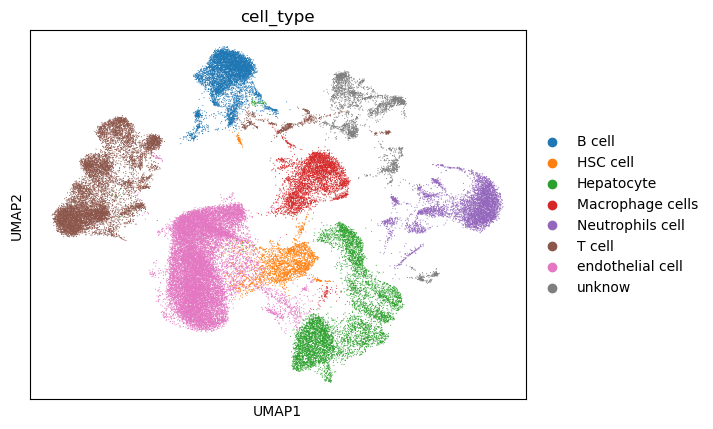

In [ ]:
sc.pl.umap(adata, color=["cell_type"],legend_loc="right margin",save="_celltype.pdf")


In [29]:
print(adata.obs.head())

                        sample  n_genes_by_counts  total_counts  \
ctrl_AAACCCAAGAGGGCGA-1   ctrl               1181        2481.0   
ctrl_AAACCCAAGTCATGGG-1   ctrl               2429        5675.0   
ctrl_AAACCCAAGTGCGACA-1   ctrl               1852        4772.0   
ctrl_AAACCCACAAGTTTGC-1   ctrl               3108        8680.0   
ctrl_AAACCCACACAGAAGC-1   ctrl               1883        4644.0   

                         total_counts_mt  pct_counts_mt leiden  \
ctrl_AAACCCAAGAGGGCGA-1              0.0            0.0      1   
ctrl_AAACCCAAGTCATGGG-1              0.0            0.0      1   
ctrl_AAACCCAAGTGCGACA-1              0.0            0.0      9   
ctrl_AAACCCACAAGTTTGC-1              0.0            0.0      0   
ctrl_AAACCCACACAGAAGC-1              0.0            0.0      0   

                                cell_type  
ctrl_AAACCCAAGAGGGCGA-1  endothelial cell  
ctrl_AAACCCAAGTCATGGG-1  endothelial cell  
ctrl_AAACCCAAGTGCGACA-1          HSC cell  
ctrl_AAACCCACAAGTTTGC-1 

In [ ]:
# Split samples
adata_ctrl = adata[adata.obs['sample'] == 'ctrl', :].copy()
adata_model = adata[adata.obs['sample'] == 'model', :].copy()

# Check cell types in each sample
cell_types_ctrl = adata_ctrl.obs['cell_type'].unique()
print(cell_types_ctrl)

cell_types_model = adata_model.obs['cell_type'].unique()
print(cell_types_model)


In [ ]:

# Control and model groups
adata_filtered = adata[adata.obs['sample'].isin(['ctrl', 'model']), :].copy()


cell_types = adata_filtered.obs['cell_type'].unique()
fold_changes = {}
log2_model_expr = {}

# Compute logFC
for cell_type in cell_types:
    ctrl_cells = adata_filtered[(adata_filtered.obs['sample'] == 'ctrl') & 
                                 (adata_filtered.obs['cell_type'] == cell_type), :].X
    model_cells = adata_filtered[(adata_filtered.obs['sample'] == 'model') & 
                                  (adata_filtered.obs['cell_type'] == cell_type), :].X
    
    ctrl_mean = np.mean(ctrl_cells, axis=0) + 1 
    model_mean = np.mean(model_cells, axis=0) + 1

    log2_model = np.log2(model_mean)

    log2_fc = np.log2(model_mean / ctrl_mean)

    fold_changes[cell_type] = log2_fc
    log2_model_expr[cell_type] = log2_model

log2_fc_df = pd.DataFrame(fold_changes, index=adata_filtered.var_names)
log2_fc_df['gene'] = log2_fc_df.index
log2_fc_df = log2_fc_df[['gene'] + list(cell_types)]

log2_model_expr_df = pd.DataFrame(log2_model_expr, index=adata_filtered.var_names) 
log2_model_expr_df['gene'] = log2_model_expr_df.index
log2_model_expr_df = log2_model_expr_df[['gene'] + list(cell_types)]

log2_fc_values = log2_fc_df.set_index('gene')
log2_fc_values = log2_fc_values.apply(pd.to_numeric, errors='coerce')

log2_fc_change_df = log2_fc_values.copy()
log2_fc_change_df = log2_fc_change_df.applymap(lambda x: 'up' if x > 0.1 else ('down' if x < -0.1 else 'stable'))

log2_fc_change_df.insert(0, 'gene', log2_fc_values.index)
log2_fc_change_df.head()

/tmp/ipykernel_27430/1870790492.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  log2_fc_change_df = log2_fc_change_df.applymap(lambda x: 'up' if x > 0.1 else ('down' if x < -0.1 else 'stable'))


,gene,endothelial cell,HSC cell,T cell,Hepatocyte,Neutrophils cell,unknow,Macrophage cells,B cell
gene,,,,,,,,,
Il17a,Il17a,stable,stable,stable,stable,stable,stable,stable,stable
Il17f,Il17f,stable,stable,stable,stable,stable,stable,stable,stable
Gsta3,Gsta3,stable,stable,stable,up,stable,stable,stable,stable
Adgrb3,Adgrb3,stable,stable,stable,stable,stable,stable,stable,stable
Gm29128,Gm29128,stable,stable,stable,stable,stable,stable,stable,stable


In [ ]:

log2_fc_df = log2_fc_df.apply(pd.to_numeric, errors='coerce') 
log2_model_expr_df = log2_model_expr_df.apply(pd.to_numeric, errors='coerce')
filtered_genes_by_cell_type = {}
cell_types = log2_fc_df.columns

for cell_type in cell_types: 
    filtered_model_genes = log2_model_expr_df[cell_type][log2_model_expr_df[cell_type] > 0.35].dropna().index
    filtered_fc_genes = log2_fc_df[cell_type][log2_fc_df[cell_type].abs() > 0.05].dropna().index
    common_genes = filtered_model_genes.intersection(filtered_fc_genes)
    filtered_genes_by_cell_type[cell_type] = common_genes

gene_counts_by_cell_type = {cell_type: len(genes) for cell_type, genes in filtered_genes_by_cell_type.items()}

for cell_type, count in gene_counts_by_cell_type.items(): 
    print(f"{cell_type}: {count} genes")

gene: 0 genes
endothelial cell: 86 genes
HSC cell: 150 genes
T cell: 102 genes
Hepatocyte: 262 genes
Neutrophils cell: 230 genes
unknow: 144 genes
Macrophage cells: 123 genes
B cell: 106 genes


In [ ]:
records = []
for cell_type, gene_list in filtered_genes_by_cell_type.items():
    if cell_type not in log2_fc_df.columns:
        continue
    for gene in gene_list:
        records.append({'cell_type': cell_type, 'gene': gene})

filtered_genes_df = pd.DataFrame(records)

print(filtered_genes_df.head())
print(filtered_genes_df.shape)

          cell_type   gene
0  endothelial cell    Dbi
1  endothelial cell  Apoa2
2  endothelial cell   Phyh
3  endothelial cell   Ass1
4  endothelial cell   Rnd3
(1203, 2)


In [ ]:
log2_fc_df_indexed = log2_fc_df.copy()

filtered_genes_df['log2_fc'] = filtered_genes_df.apply(lambda row: log2_fc_df_indexed.loc[row['gene'], row['cell_type']], axis=1)
filtered_genes_df


             cell_type     gene   log2_fc
0     endothelial cell      Dbi  0.143361
1     endothelial cell    Apoa2 -0.159203
2     endothelial cell     Phyh  0.104045
3     endothelial cell     Ass1  0.324539
4     endothelial cell     Rnd3  0.090861
...                ...      ...       ...
1198            B cell    Ms4a1  0.053063
1199            B cell     Blnk  0.050295
1200            B cell     Scd1 -0.087247
1201            B cell  mt-Atp8 -0.098222
1202            B cell   mt-Nd3 -0.063435

[1203 rows x 3 columns]


In [ ]:

gene_counts = filtered_genes_df['gene'].value_counts()
common_genes = gene_counts[gene_counts >= 1].index.tolist()
common_genes_df = filtered_genes_df[filtered_genes_df['gene'].isin(common_genes)]

print(common_genes_df['gene'].nunique())
print(common_genes_df.head())

659
          cell_type   gene   log2_fc
0  endothelial cell    Dbi  0.143361
1  endothelial cell  Apoa2 -0.159203
2  endothelial cell   Phyh  0.104045
3  endothelial cell   Ass1  0.324539
4  endothelial cell   Rnd3  0.090861


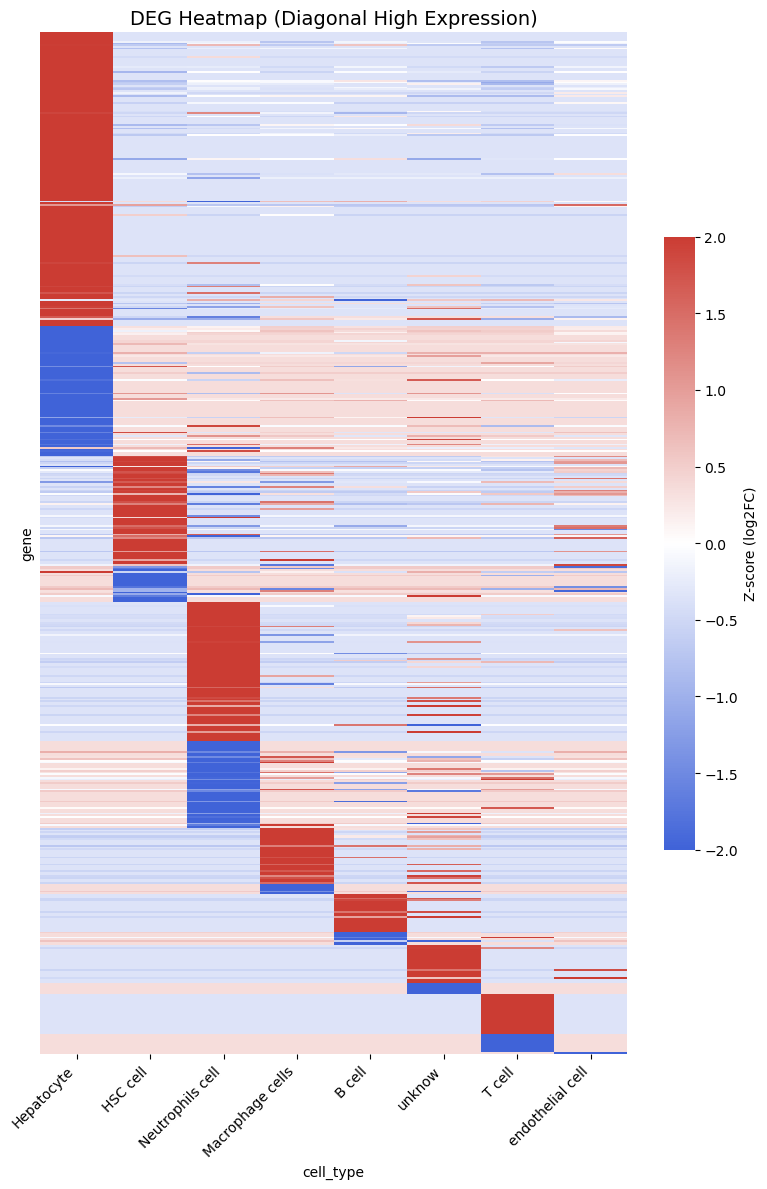

In [ ]:
# DEG heatmap
heatmap_data = common_genes_df.pivot(index='gene', columns='cell_type', values='log2_fc')
heatmap_data = heatmap_data.fillna(0)

desired_order = [
    'Hepatocyte','HSC cell','Neutrophils cell', 'Macrophage cells', 'B cell', 
    'unknow', 'T cell', 'endothelial cell'  
]

valid_order = [c for c in desired_order if c in heatmap_data.columns]
heatmap_data = heatmap_data[valid_order]

gene_source = common_genes_df.drop_duplicates(subset=["gene"])[["gene", "cell_type"]].set_index("gene")
cell_order_dict = {cell: i for i, cell in enumerate(valid_order)}
gene_scores = gene_source["cell_type"].map(cell_order_dict)
sorted_gene_list = []

for cell in valid_order:
    fc_values = heatmap_data[cell]
    up_genes = fc_values[fc_values > 0].sort_values(ascending=False).index.tolist()
    down_genes = fc_values[fc_values < 0].sort_values().index.tolist()
    sorted_gene_list.extend(up_genes + down_genes)

from collections import OrderedDict
sorted_gene_list = list(OrderedDict.fromkeys(sorted_gene_list))

heatmap_data_sorted = heatmap_data.loc[sorted_gene_list, valid_order]


heatmap_data_scaled = heatmap_data_sorted.sub(
    heatmap_data_sorted.mean(axis=1), axis=0
).div(
    heatmap_data_sorted.std(axis=1), axis=0
).fillna(0)

my_cmap = LinearSegmentedColormap.from_list(
    "refined",
    ["#4063D8", "white", "#CB3C33"]
)

plt.figure(figsize=(8, 12))
sns.heatmap(
    heatmap_data_scaled,
    cmap=my_cmap,
    vmin=-2, vmax=2, center=0,
    xticklabels=True, yticklabels=False,
    cbar_kws={'label': 'Z-score (log2FC)', 'shrink': 0.6}
)

plt.title("DEG Heatmap (Diagonal High Expression)", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("figures/heatmap_logFC_scaled.pdf", dpi=300)
plt.show()


In [ ]:
import os

output_dir = "PPI_gene_lists"
os.makedirs(output_dir, exist_ok=True)

for cell_type, genes in filtered_genes_by_cell_type.items():
    file_path = os.path.join(output_dir, f"{cell_type}_PPI_genes.txt")
    with open(file_path, "w") as f:
        for gene in genes:
            f.write(gene + "\n")



In [ ]:
import requests
import time

STRING_API_URL = "https://string-db.org/api/json/network"
session_id = "bTl1lWcBu0HL"

ppi_results = {}

for cell_type, genes in filtered_genes_by_cell_type.items():
    print(f"Processing {cell_type}...")

    gene_list_str = "%0d".join(genes)

    params = {
        "identifiers": gene_list_str,
        "species": 10090,
        "required_score": 400,
        "sessionId": session_id,
    }

    response = requests.get(STRING_API_URL, params=params)

    if response.status_code == 200:
        ppi_results[cell_type] = response.json()
        print(f"{cell_type} PPI succeed!")
    else:
        print(f"{cell_type} failure, code: {response.status_code}")

    time.sleep(1)

print("Done!")

In [ ]:
import os
import json

output_folder = "PPI_result"
os.makedirs(output_folder, exist_ok=True)

for cell_type, result in ppi_results.items():
    file_path = os.path.join(output_folder, f"{cell_type}_PPI.json")
    with open(file_path, "w") as f:
        json.dump(result, f, indent=4)

print(f"Saved results to {output_folder}")

In [ ]:
# Compute centrality
import os
import json
import networkx as nx
import pandas as pd

ppi_folder = "PPI_result"
degree_centrality_by_cell_type = {}

for file_name in os.listdir(ppi_folder):
    if file_name.endswith("_PPI.json"):
        cell_type = file_name.replace("_PPI.json", "")
        file_path = os.path.join(ppi_folder, file_name)

        with open(file_path, "r") as f:
            ppi_data = json.load(f)

        G = nx.Graph()
        for interaction in ppi_data:
            protein1 = interaction["preferredName_A"]
            protein2 = interaction["preferredName_B"]
            G.add_edge(protein1, protein2)

        degree_centrality =  dict(G.degree())
        degree_centrality_by_cell_type[cell_type] = degree_centrality

df_list = []
for cell_type, centrality_dict in degree_centrality_by_cell_type.items():
    df = pd.DataFrame(centrality_dict.items(), columns=["Gene", "Degree Centrality"])
    df["Cell Type"] = cell_type
    df_list.append(df)

degree_centrality_df = pd.concat(df_list, ignore_index=True)
degree_centrality_df.head()

,Gene,Degree Centrality,Cell Type
0,Apoh,72,Hepatocyte
1,Cyp3a11,59,Hepatocyte
2,Baat,23,Hepatocyte
3,Hpd,57,Hepatocyte
4,Agt,28,Hepatocyte


In [ ]:
cell_types = degree_centrality_df["Cell Type"].unique()
cell_types

['Hepatocyte' 'HSC cell' 'unknow' 'B cell' 'T cell' 'endothelial cell'
 'Macrophage cells' 'Neutrophils cell']


In [ ]:
# Compute RL index

rl_results = {}

for cell_type in degree_centrality_df["Cell Type"].unique():
    ppi_genes = degree_centrality_df[degree_centrality_df["Cell Type"] == cell_type]["Gene"]
    valid_genes = [gene for gene in ppi_genes if gene in adata.var_names]
    ctrl_expr = np.mean(adata[adata.obs["sample"] == "ctrl"][:, valid_genes].X, axis=0) + 1
    model_expr = np.mean(adata[adata.obs["sample"] == "model"][:, valid_genes].X, axis=0) + 1
    drug_expr = np.mean(adata[adata.obs["sample"] == "drug"][:, valid_genes].X, axis=0) + 1
    log_ctrl = np.log2(ctrl_expr)
    log_model = np.log2(model_expr)
    log_drug = np.log2(drug_expr)
    

    rl_values = (log_drug - log_model) / (log_ctrl - log_model)
    rl_results[cell_type] = pd.DataFrame({
        "Gene": valid_genes,
        "RL": rl_values
    })


rl_df = pd.concat(rl_results, keys=rl_results.keys()).reset_index()
rl_df.rename(columns={"level_0": "Cell Type"}, inplace=True)


rl_df.head()

,Cell Type,level_1,Gene,RL
0,Hepatocyte,0,Apoh,2.772769
1,Hepatocyte,1,Cyp3a11,15.846054
2,Hepatocyte,2,Baat,1.018998
3,Hepatocyte,3,Hpd,0.824376
4,Hepatocyte,4,Agt,-4.023079


In [42]:
cell_types = rl_df["Cell Type"].unique()
print(cell_types)


['Hepatocyte' 'HSC cell' 'unknow' 'B cell' 'T cell' 'endothelial cell'
 'Macrophage cells' 'Neutrophils cell']


In [ ]:
# Compute EoR
EoR_df = pd.DataFrame(columns=["Cell Type", "Gene", "RL", "EoR", "Change"])

for cell_type in log2_fc_change_df.columns[1:]:
    up_genes = log2_fc_change_df[log2_fc_change_df[cell_type] == "up"]["gene"]
    down_genes = log2_fc_change_df[log2_fc_change_df[cell_type] == "down"]["gene"]
    selected_genes = pd.concat([up_genes, down_genes])
    
    selected_rl = rl_df[(rl_df["Cell Type"] == cell_type) & (rl_df["Gene"].isin(selected_genes))].copy()
    valid_genes = [gene for gene in selected_rl["Gene"] if gene in adata.var_names]
    if not valid_genes:
        continue
        
    ctrl_expr = np.mean(adata[adata.obs["sample"] == "ctrl"][:, valid_genes].X, axis=0) + 1
    model_expr = np.mean(adata[adata.obs["sample"] == "model"][:, valid_genes].X, axis=0) + 1
    
    log_ctrl = np.log2(ctrl_expr)
    log_model = np.log2(model_expr)
    EoR_1 = np.abs(log_model - log_ctrl)
    EoR= (EoR_1 > 0.5).astype(int)
    selected_rl = selected_rl[selected_rl["Gene"].isin(valid_genes)]
    selected_rl = selected_rl.set_index("Gene").loc[valid_genes].reset_index()


    selected_rl["EoR"] = EoR

    selected_rl = selected_rl[(selected_rl["EoR"] >= 0) & (selected_rl["EoR"] <= 2)]
    selected_rl["Change"] = selected_rl["Gene"].map(
        lambda g: "up" if g in up_genes.values else "down"
    )
    
    EoR_df = pd.concat([EoR_df, selected_rl])

EoR_df.reset_index(drop=True, inplace=True)

EoR_df.head()


/tmp/ipykernel_27430/1852207578.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  EoR_df = pd.concat([EoR_df, selected_rl])


,Cell Type,Gene,RL,EoR,Change,level_1
0,endothelial cell,Ccl2,1.416327,0,up,0.0
1,endothelial cell,Ifit3,0.231961,0,up,3.0
2,endothelial cell,Apoa1,-6.982156,0,down,5.0
3,endothelial cell,Tnfaip3,4.466432,0,up,7.0
4,endothelial cell,Ifit1,-0.298622,0,up,8.0


In [44]:
unique_changes = EoR_df['Change'].value_counts()
print(unique_changes)


Change
up      426
down    175
Name: count, dtype: int64


In [ ]:
import pandas as pd

RR_updown = EoR_df.merge(
    degree_centrality_df[["Gene", "Cell Type","Degree Centrality"]],
    on=["Gene", "Cell Type"],
    how="left"
)


In [ ]:
# Compute RR
RR_updown["RR_updown"] = RR_updown["EoR"] * RR_updown["Degree Centrality"]

print(RR_updown.head())

          Cell Type     Gene        RL EoR Change  level_1  Degree Centrality  \
0  endothelial cell     Ccl2  1.416327   0     up      0.0                 19   
1  endothelial cell    Ifit3  0.231961   0     up      3.0                  5   
2  endothelial cell    Apoa1 -6.982156   0   down      5.0                 21   
3  endothelial cell  Tnfaip3  4.466432   0     up      7.0                 10   
4  endothelial cell    Ifit1 -0.298622   0     up      8.0                  8   

  RR_updown  
0         0  
1         0  
2         0  
3         0  
4         0  


In [ ]:
# Compute EoR for all cell types
EoR_all_list = []

for cell_type in rl_df["Cell Type"].unique():
    sub_df = rl_df[rl_df["Cell Type"] == cell_type].copy()

    sub_df["EoR_all"] = 1 - abs(1 - sub_df["RL"])
    sub_df = sub_df[(sub_df["EoR_all"] > 0) & (sub_df["EoR_all"] < 2)]
    sub_df["Cell Type"] = cell_type
    EoR_all_list.append(sub_df[["Cell Type", "Gene", "RL", "EoR_all"]])

EoR_all_df = pd.concat(EoR_all_list, ignore_index=True)

EoR_all_df.head()

,Cell Type,Gene,RL,EoR_all
0,Hepatocyte,Baat,1.018998,0.981002
1,Hepatocyte,Hpd,0.824376,0.824376
2,Hepatocyte,Lrg1,0.701369,0.701369
3,Hepatocyte,Angptl3,1.083517,0.916483
4,Hepatocyte,Tdo2,0.889313,0.889313


In [ ]:
RR_all = EoR_all_df.merge(
    degree_centrality_df[["Gene", "Cell Type", "Degree Centrality"]],
    on=["Gene", "Cell Type"],
    how="left"
)

RR_all["RR_all"] = RR_all["EoR_all"] * RR_all["Degree Centrality"]

print(RR_all.head())

    Cell Type     Gene        RL   EoR_all  Degree Centrality     RR_all
0  Hepatocyte     Baat  1.018998  0.981002                 23  22.563037
1  Hepatocyte      Hpd  0.824376  0.824376                 57  46.989455
2  Hepatocyte     Lrg1  0.701369  0.701369                 15  10.520531
3  Hepatocyte  Angptl3  1.083517  0.916483                 21  19.246136
4  Hepatocyte     Tdo2  0.889313  0.889313                 34  30.236658


In [ ]:
df_updown = RR_updown[["Cell Type", "Gene", "RR_updown"]].copy()
df_all = RR_all[["Cell Type", "Gene", "RR_all", "Degree Centrality"]].copy()

RR_df = pd.merge(df_all, df_updown, on=["Cell Type", "Gene"], how="left")
RR_df["RR_updown"] = RR_df["RR_updown"].fillna(0)

print(RR_df.head())


    Cell Type     Gene  RR_updown     RR_all  Degree Centrality
0  Hepatocyte     Baat          0  22.563037                 23
1  Hepatocyte      Hpd          0  46.989455                 57
2  Hepatocyte     Lrg1          0  10.520531                 15
3  Hepatocyte  Angptl3          0  19.246136                 21
4  Hepatocyte     Tdo2          0  30.236658                 34


/tmp/ipykernel_27430/3236497438.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  RR_df["RR_updown"] = RR_df["RR_updown"].fillna(0)


In [ ]:
RR_df['NRI'] = RR_df['RR_updown'] + RR_df['RR_all']


In [ ]:
import pandas as pd


edges_list = []
node_annotations = {}

for cell_type, interactions in ppi_results.items():
    for interaction in interactions:
        protein1 = interaction["preferredName_A"]
        protein2 = interaction["preferredName_B"]
        score = interaction["score"]

        edges_list.append((protein1, protein2, score))

        if protein1 not in node_annotations:
            node_annotations[protein1] = set()
        node_annotations[protein1].add(cell_type)

        if protein2 not in node_annotations:
            node_annotations[protein2] = set()
        node_annotations[protein2].add(cell_type)

edges_df = pd.DataFrame(edges_list, columns=["source", "target", "score"])
edges_df.drop_duplicates(inplace=True)

nodes_df = pd.DataFrame([
    {"gene": gene, "cell_types": ";".join(sorted(types))}
    for gene, types in node_annotations.items()
])

output_dir = "PPI_merged_for_Cytoscape"
os.makedirs(output_dir, exist_ok=True)

edges_df.to_csv(os.path.join(output_dir, "edges.tsv"), sep="\t", index=False)
nodes_df.to_csv(os.path.join(output_dir, "nodes.tsv"), sep="\t", index=False)

In [ ]:

gene_fc_summary = (
    filtered_genes_df
    .assign(abs_log2_fc = filtered_genes_df["log2_fc"].abs())
    .groupby("gene")["abs_log2_fc"]
    .mean()
    .reset_index()
    .rename(columns={"abs_log2_fc": "mean_abs_log2_fc"})
)

rr_multi = (
    RR_df
    .groupby("Gene")[["RR_updown", "RR_all", "NRI"]]
    .mean()
    .reset_index()
    .rename(columns={"Gene": "gene"})
)

nodes_df = nodes_df.merge(gene_fc_summary, how="left", on="gene")
nodes_df = nodes_df.merge(rr_multi, how="left", on="gene")

output_dir = "PPI_merged_for_Cytoscape"
os.makedirs(output_dir, exist_ok=True)

nodes_df.to_csv(os.path.join(output_dir, "nodes.tsv"), sep="\t", index=False)
edges_df.to_csv(os.path.join(output_dir, "edges.tsv"), sep="\t", index=False)


In [ ]:
NRI_df = RR_df.groupby('Cell Type', as_index=False)['NRI'].sum()

print(NRI_df)

          Cell Type          NRI
0            B cell   262.928101
1          HSC cell   264.802539
2        Hepatocyte  2230.640630
3  Macrophage cells   286.149134
4  Neutrophils cell   466.500827
5            T cell   358.973783
6  endothelial cell   211.368936
7            unknow   382.181275


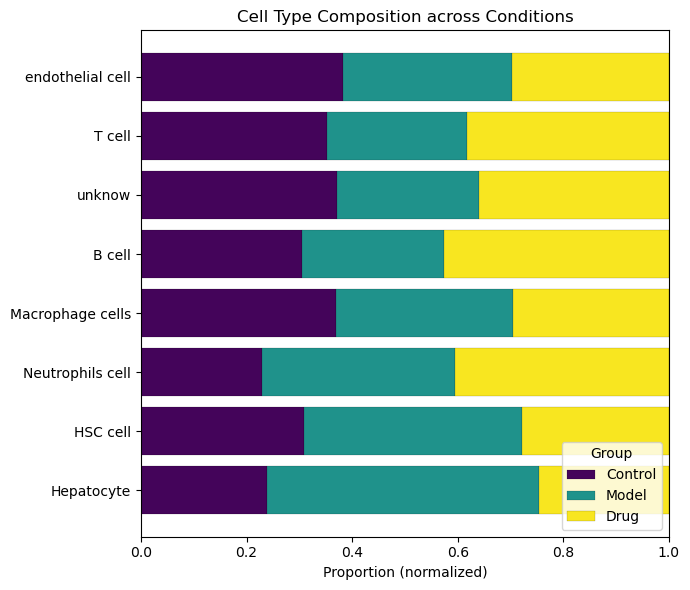

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

ct_counts = pd.crosstab(adata.obs['sample'], adata.obs['cell_type'])
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)
grouped = {
    'control': ct_props.loc[ct_props.index.str.contains("ctrl")].mean(),
    'model': ct_props.loc[ct_props.index.str.contains("model")].mean(),
    'drug': ct_props.loc[ct_props.index.str.contains("drug")].mean(),
}
df = pd.DataFrame(grouped)

cell_order = [
    'Hepatocyte','HSC cell','Neutrophils cell', 'Macrophage cells', 'B cell', 
    'unknow', 'T cell', 'endothelial cell'  
]
cell_order_valid = [ct for ct in cell_order if ct in df.index]

df = df.loc[cell_order_valid]
df_norm = df.div(df.sum(axis=1), axis=0)

colors = {
    'control': '#44045A',   
    'model': '#1F928B',    
    'drug': '#F8E620'      
}

fig, ax = plt.subplots(figsize=(7, 6))

left = [0] * len(df_norm)
for group in ['control', 'model', 'drug']:
    ax.barh(df_norm.index, df_norm[group], left=left,
            label=group.capitalize(), color=colors[group],
            edgecolor='black',linewidth=0.1)

    left = [i + j for i, j in zip(left, df_norm[group])]


ax.set_xlim(0, 1)
ax.set_xlabel("Proportion (normalized)")
ax.set_title("Cell Type Composition across Conditions")
ax.legend(title="Group", loc='lower right')
plt.tight_layout()
plt.savefig("figures/cell_type_proportions.pdf", format='pdf')
plt.show()

CCI recovery index

In [ ]:
import liana
import pandas as pd

expression_matrix = adata.raw.X
cell_types = adata.obs['cell_type']
metadata = adata.obs[['sample', 'cell_type']]
receptor_ligand_database = "interaction_table.csv"


In [ ]:
from liana.method import cellphonedb
adata.raw = adata
cellphonedb(
    adata=adata,
    groupby='cell_type',
    resource_name='mouseconsensus',  
    expr_prop=0.01,
    min_cells=2,
    de_method='t-test',
    n_perms=1000,
    seed=1337,
    n_jobs=1,
    verbose=True
)

adata.uns['liana_res'].head()

Using resource `mouseconsensus`.
Using `.raw`!
Converting to sparse csr matrix!
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:153: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
0.78 of entities in the resource are missing from the data.


Generating ligand-receptor stats for 55668 samples and 181 features


100%|██████████| 1000/1000 [00:12<00:00, 79.31it/s]


,ligand,ligand_complex,ligand_means,ligand_props,receptor,receptor_complex,receptor_means,receptor_props,source,target,lr_means,cellphone_pvals
2906,S100a9,S100a9,5.817437,0.994806,Cd68,Cd68,1.486303,0.780376,Neutrophils cell,Macrophage cells,3.651870,0.0
6267,S100a9,S100a9,5.817437,0.994806,Cd68,Cd68,0.645799,0.572822,Neutrophils cell,unknow,3.231618,0.0
3844,S100a9,S100a9,5.817437,0.994806,Cd68,Cd68,0.327434,0.230523,Neutrophils cell,Neutrophils cell,3.072435,0.0
4788,S100a8,S100a8,4.516589,0.986416,Cd69,Cd69,1.490295,0.736294,Neutrophils cell,T cell,3.003442,0.0
2905,S100a8,S100a8,4.516589,0.986416,Cd68,Cd68,1.486303,0.780376,Neutrophils cell,Macrophage cells,3.001446,0.0


In [ ]:
# Run Liana for each group
smi_adata = adata[adata.obs['sample'] == 'drug'].copy()
model_adata = adata[adata.obs['sample'] == 'model'].copy()
ctrl_adata = adata[adata.obs['sample'] == 'ctrl'].copy()

print(smi_adata.shape)
print(model_adata.shape)
print(ctrl_adata.shape)


smi_results = cellphonedb(
    adata=smi_adata,
    groupby='cell_type',
    resource_name='mouseconsensus',  
    expr_prop=0.01,
    min_cells=2,
    de_method='t-test',
    n_perms=1000,
    seed=1337,
    n_jobs=1,
    verbose=True
)
model_results = cellphonedb(
    adata=model_adata,
    groupby='cell_type',
    resource_name='mouseconsensus',  
    expr_prop=0.01,
    min_cells=2,
    de_method='t-test',
    n_perms=1000,
    seed=1337,
    n_jobs=1,
    verbose=True
)
ctrl_results = cellphonedb(
    adata=ctrl_adata,
    groupby='cell_type',
    resource_name='mouseconsensus',  
    expr_prop=0.01,
    min_cells=2,
    de_method='t-test',
    n_perms=1000,
    seed=1337,
    n_jobs=1,
    verbose=True
)

Using resource `mouseconsensus`.
Using `.raw`!
Converting to sparse csr matrix!


(17072, 2000)
(19155, 2000)
(19441, 2000)


/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
105 features of mat are empty, they will be removed.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:150: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:153: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
0.78 of entities in the resource are missing from the data.


Generating ligand-receptor stats for 17072 samples and 180 features


100%|██████████| 1000/1000 [00:04<00:00, 220.61it/s]
Using resource `mouseconsensus`.
Using `.raw`!
Converting to sparse csr matrix!
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
111 features of mat are empty, they will be removed.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:150: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:153: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
0.79 of entities in the resource are missing from th

Generating ligand-receptor stats for 19155 samples and 177 features


100%|██████████| 1000/1000 [00:05<00:00, 197.35it/s]
Using resource `mouseconsensus`.
Using `.raw`!
Converting to sparse csr matrix!
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
82 features of mat are empty, they will be removed.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:150: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:153: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
0.79 of entities in the resource are missing from the

Generating ligand-receptor stats for 19441 samples and 178 features


100%|██████████| 1000/1000 [00:04<00:00, 205.52it/s]


In [238]:
ctrl_adata.uns['liana_res'].head()

,ligand,ligand_complex,ligand_means,ligand_props,receptor,receptor_complex,receptor_means,receptor_props,source,target,lr_means,cellphone_pvals
2966,S100a9,S100a9,5.481752,0.992574,Cd68,Cd68,1.433123,0.764550,Neutrophils cell,Macrophage cells,3.457438,0.0
6157,S100a9,S100a9,5.481752,0.992574,Cd68,Cd68,0.577680,0.521467,Neutrophils cell,unknow,3.029716,0.0
3853,S100a9,S100a9,5.481752,0.992574,Cd68,Cd68,0.257327,0.166667,Neutrophils cell,Neutrophils cell,2.869539,0.0
3869,Cxcl2,Cxcl2,4.376589,0.970297,Cxcr2,Cxcr2,1.308735,0.667492,Neutrophils cell,Neutrophils cell,2.842662,0.0
3977,Ccl5,Ccl5,1.872356,0.501415,Ccrl2,Ccrl2,3.783414,0.981848,T cell,Neutrophils cell,2.827885,0.0


In [ ]:
import pandas as pd

drug_df = smi_adata.uns['liana_res'].groupby(['source', 'target'])['lr_means'].mean().reset_index()
drug_df.rename(columns={'lr_means': 'value'}, inplace=True)

drug_df = drug_df[['source', 'target', 'value']]

drug_df.to_csv('figures/drug_chord.csv', index=False)


In [ ]:
import pandas as pd

ctrl_df = ctrl_adata.uns['liana_res'].groupby(['source', 'target'])['lr_means'].mean().reset_index()
ctrl_df.rename(columns={'lr_means': 'ctrl'}, inplace=True)

model_df = model_adata.uns['liana_res'].groupby(['source', 'target'])['lr_means'].mean().reset_index()
model_df.rename(columns={'lr_means': 'model'}, inplace=True)

smi_df = smi_adata.uns['liana_res'].groupby(['source', 'target'])['lr_means'].mean().reset_index()
smi_df.rename(columns={'lr_means': 'smi'}, inplace=True)
smi_df.to_csv("figures/smi_chord_data.csv", index=False)
merged_df = ctrl_df.merge(model_df, on=['source', 'target'], how='outer')
merged_df = merged_df.merge(smi_df, on=['source', 'target'], how='outer')
merged_df = merged_df.fillna(0)
merged_df['model_vs_ctrl'] = merged_df['model'] - merged_df['ctrl']
merged_df['smi_vs_ctrl'] = merged_df['smi'] - merged_df['ctrl']
model_diff_df = merged_df[merged_df['model_vs_ctrl'].abs() > 0.01][['source', 'target', 'model_vs_ctrl']]
smi_diff_df = merged_df[merged_df['smi_vs_ctrl'].abs() > 0.01][['source', 'target', 'smi_vs_ctrl']]

model_diff_df.columns = ['source', 'target', 'value']
smi_diff_df.columns = ['source', 'target', 'value']

model_diff_df.to_csv('figures/model_vs_ctrl_chord.csv', index=False)
smi_diff_df.to_csv('figures/smi_vs_ctrl_chord.csv', index=False)


In [ ]:
smi_results = smi_adata.uns['liana_res']
model_results = model_adata.uns['liana_res']
ctrl_results = ctrl_adata.uns['liana_res']

smi_results_filtered = smi_results[smi_results['cellphone_pvals'] < 0.05]
model_results_filtered = model_results[model_results['cellphone_pvals'] < 0.05]
ctrl_results_filtered = ctrl_results[ctrl_results['cellphone_pvals'] < 0.05]

smi_results_filtered = smi_results_filtered[['ligand', 'receptor', 'lr_means', 'source', 'target']]
model_results_filtered = model_results_filtered[['ligand', 'receptor', 'lr_means', 'source', 'target']]
ctrl_results_filtered = ctrl_results_filtered[['ligand', 'receptor', 'lr_means', 'source', 'target']]

merged_results = pd.merge(smi_results_filtered, model_results_filtered, on=['ligand', 'receptor', 'source', 'target'], suffixes=('_smi', '_model'))
merged_results = pd.merge(merged_results, ctrl_results_filtered, on=['ligand', 'receptor', 'source', 'target'])

merged_results['IAB_g1g2_smi'] = merged_results['lr_means_smi']
merged_results['IAB_g1g2_model'] = merged_results['lr_means_model']
merged_results['IAB_g1g2_ctrl'] = merged_results['lr_means']

merged_results['RLAB_g1g2'] = (merged_results['IAB_g1g2_smi'] - merged_results['IAB_g1g2_model']) / (merged_results['IAB_g1g2_ctrl'] - merged_results['IAB_g1g2_model'])

print(merged_results[['ligand', 'receptor', 'source', 'target', 'RLAB_g1g2']].head())


   ligand receptor            source            target  RLAB_g1g2
0  S100a9     Cd68  Neutrophils cell  Macrophage cells  -0.079213
1  S100a9     Cd68  Neutrophils cell            unknow  -0.015303
2  S100a9     Cd68  Neutrophils cell  Neutrophils cell  -0.128085
3  S100a8     Cd68  Neutrophils cell  Macrophage cells  -0.025517
4  S100a8     Cd69  Neutrophils cell            T cell  -0.169005


In [ ]:
import numpy as np

merged_results['EoRCAB_g1g2'] = np.where(
    (1 - np.abs(1 - merged_results['RLAB_g1g2'])) <= 0, 
    0, 
    1
)

print(merged_results[['ligand', 'receptor', 'source', 'target', 'RLAB_g1g2', 'EoRCAB_g1g2']].head())


   ligand receptor            source            target  RLAB_g1g2  EoRCAB_g1g2
0  S100a9     Cd68  Neutrophils cell  Macrophage cells  -0.079213            0
1  S100a9     Cd68  Neutrophils cell            unknow  -0.015303            0
2  S100a9     Cd68  Neutrophils cell  Neutrophils cell  -0.128085            0
3  S100a8     Cd68  Neutrophils cell  Macrophage cells  -0.025517            0
4  S100a8     Cd69  Neutrophils cell            T cell  -0.169005            0


In [61]:
import os
import json
import networkx as nx
from itertools import combinations
from collections import defaultdict


In [ ]:

ppi_dir = "PPI_result"
ppi_graphs = {}

for file in os.listdir(ppi_dir):
    if file.endswith("_PPI.json"):
        cell_type = file.replace("_PPI.json", "")
        with open(os.path.join(ppi_dir, file)) as f:
            interactions = json.load(f)

        G = nx.Graph()
        for entry in interactions:
            g1 = entry['preferredName_A']
            g2 = entry['preferredName_B']
            score = entry.get('score', 0.0)
            G.add_edge(g1, g2, weight=score)
        
        ppi_graphs[cell_type] = G


In [ ]:
cell_type_pairs = list(combinations(ppi_graphs.keys(), 2))

bc_results = defaultdict(dict)


In [ ]:
# Compute intersection graph for cell type pairs
for ct1, ct2 in cell_type_pairs:

    G1 = ppi_graphs[ct1]
    G2 = ppi_graphs[ct2]

    G_union = nx.compose(G1, G2)

    bc = nx.betweenness_centrality(G_union, normalized=True)
    bc_results[(ct1, ct2)] = bc


In [65]:
lr_centrality_scores = []

for _, row in merged_results.iterrows():
    ct_pair = tuple(sorted([row['source'], row['target']]))
    g1 = row['ligand']
    g2 = row['receptor']

    bc_dict = bc_results.get(ct_pair, {})

    bc_g1 = bc_dict.get(g1, 0.0)
    bc_g2 = bc_dict.get(g2, 0.0)

    lr_centrality_scores.append({
        'source': row['source'],
        'target': row['target'],
        'ligand': g1,
        'receptor': g2,
        'BC_AB_g1': bc_g1,
        'BC_AB_g2': bc_g2
    })
    
import pandas as pd
B_centrality_df = pd.DataFrame(lr_centrality_scores)


In [ ]:
# Compute averaged centrality for ligand/receptor
B_centrality_df['BC_AB_g1g2'] = (B_centrality_df['BC_AB_g1'] + B_centrality_df['BC_AB_g2']) / 2
print(B_centrality_df.head())


             source            target  ligand receptor  BC_AB_g1  BC_AB_g2  \
0  Neutrophils cell  Macrophage cells  S100a9     Cd68  0.007180   0.01824   
1  Neutrophils cell            unknow  S100a9     Cd68  0.000000   0.00000   
2  Neutrophils cell  Neutrophils cell  S100a9     Cd68  0.000000   0.00000   
3  Neutrophils cell  Macrophage cells  S100a8     Cd68  0.003658   0.01824   
4  Neutrophils cell            T cell  S100a8     Cd69  0.000000   0.00000   

   BC_AB_g1g2  
0    0.012710  
1    0.000000  
2    0.000000  
3    0.010949  
4    0.000000  


In [ ]:
BC_results = merged_results.merge(B_centrality_df, on=['source', 'target', 'ligand', 'receptor'], how='left')

BC_results['EoRCAB_g1g2'] = (1 - abs(1 - BC_results['RLAB_g1g2'])) > 0
BC_results['EoRCAB_g1g2'] = BC_results['EoRCAB_g1g2'].astype(int)

print(BC_results.head())


   ligand receptor  lr_means_smi            source            target  \
0  S100a9     Cd68      3.733107  Neutrophils cell  Macrophage cells   
1  S100a9     Cd68      3.309133  Neutrophils cell            unknow   
2  S100a9     Cd68      3.153457  Neutrophils cell  Neutrophils cell   
3  S100a8     Cd68      3.102880  Neutrophils cell  Macrophage cells   
4  S100a8     Cd69      3.086715  Neutrophils cell            T cell   

   lr_means_model  lr_means  IAB_g1g2_smi  IAB_g1g2_model  IAB_g1g2_ctrl  \
0        3.712873  3.457438      3.733107        3.712873       3.457438   
1        3.304921  3.029716      3.309133        3.304921       3.029716   
2        3.121221  2.869539      3.153457        3.121221       2.869539   
3        3.093520  2.726697      3.102880        3.093520       2.726697   
4        3.042480  2.780743      3.086715        3.042480       2.780743   

   RLAB_g1g2  EoRCAB_g1g2  BC_AB_g1  BC_AB_g2  BC_AB_g1g2  
0  -0.079213            0  0.007180   0.01824    0

In [68]:
BC_results["CCRS_ABg1g2"] = BC_results["EoRCAB_g1g2"] * BC_results["BC_AB_g1g2"]
print(BC_results[["source","target","ligand", "receptor", "EoRCAB_g1g2", "BC_AB_g1g2", "CCRS_ABg1g2"]].head())


             source            target  ligand receptor  EoRCAB_g1g2  \
0  Neutrophils cell  Macrophage cells  S100a9     Cd68            0   
1  Neutrophils cell            unknow  S100a9     Cd68            0   
2  Neutrophils cell  Neutrophils cell  S100a9     Cd68            0   
3  Neutrophils cell  Macrophage cells  S100a8     Cd68            0   
4  Neutrophils cell            T cell  S100a8     Cd69            0   

   BC_AB_g1g2  CCRS_ABg1g2  
0    0.012710          0.0  
1    0.000000          0.0  
2    0.000000          0.0  
3    0.010949          0.0  
4    0.000000          0.0  


In [ ]:
# Compute CCRS_AB
ccrs_df = (
    BC_results
    .groupby(['source', 'target'])
    .apply(lambda df: (df['BC_AB_g1g2'] * df['EoRCAB_g1g2']).sum())
    .reset_index(name='CCRS_AB')
)
print(ccrs_df.head())


   source            target   CCRS_AB
0  B cell            B cell  0.000000
1  B cell          HSC cell  0.000000
2  B cell        Hepatocyte  0.000000
3  B cell  Macrophage cells  0.029740
4  B cell  Neutrophils cell  0.281937


/tmp/ipykernel_27430/757550092.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


In [ ]:
Rank essential CCI pairs
ccrs_df_sorted = ccrs_df.sort_values(by='CCRS_AB', ascending=False)
print(ccrs_df_sorted.head(10))

              source            target   CCRS_AB
14          HSC cell            unknow  0.521470
11          HSC cell  Neutrophils cell  0.514284
12          HSC cell            T cell  0.391707
22        Hepatocyte            unknow  0.332302
13          HSC cell  endothelial cell  0.314012
27  Macrophage cells  Neutrophils cell  0.314010
4             B cell  Neutrophils cell  0.281937
10          HSC cell  Macrophage cells  0.267068
19        Hepatocyte  Neutrophils cell  0.257845
52  endothelial cell            T cell  0.178806


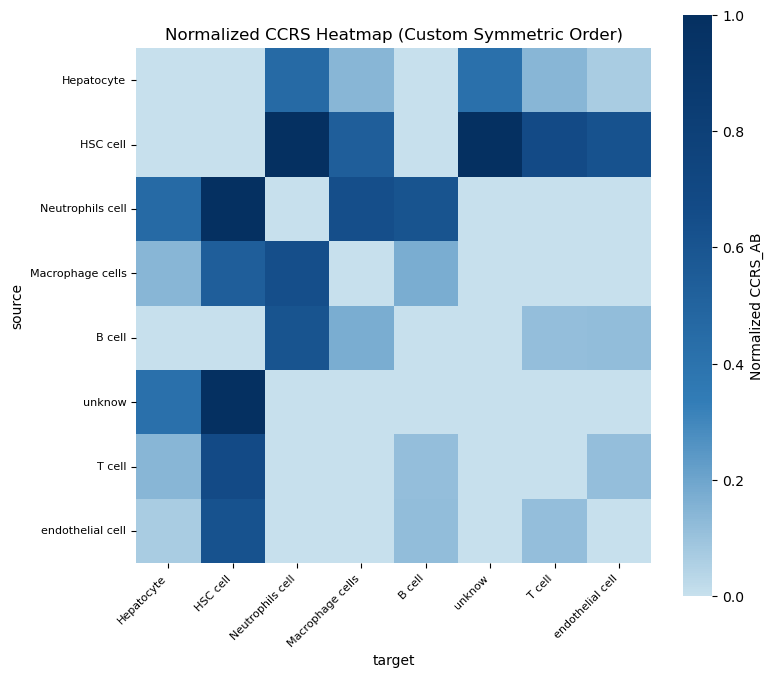

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

df_sym = pd.concat([
    ccrs_df,
    ccrs_df.rename(columns={'source': 'target', 'target': 'source'})
])
df_sym = df_sym.groupby(['source', 'target'], as_index=False).mean()

ccrs_matrix = df_sym.pivot(index='source', columns='target', values='CCRS_AB')

custom_order = [
    'Hepatocyte','HSC cell','Neutrophils cell', 'Macrophage cells', 'B cell', 
    'unknow', 'T cell', 'endothelial cell'
]

ccrs_matrix = ccrs_matrix.reindex(index=custom_order, columns=custom_order)
ccrs_matrix = ccrs_matrix.fillna(0)
vmax_val = np.percentile(ccrs_matrix.values.flatten(), 95)
ccrs_norm_clip = np.clip(ccrs_matrix, None, vmax_val)
ccrs_norm_clip = (ccrs_norm_clip - ccrs_norm_clip.min().min()) / (vmax_val - ccrs_norm_clip.min().min())
my_cmap = LinearSegmentedColormap.from_list(
    "refined",
    [ "#C7E0ED", "#327DB7","#134B87", "#053061"]
)

plt.figure(figsize=(8, 7))
ax = sns.heatmap(
    ccrs_norm_clip,
    cmap=my_cmap,
    square=True,
    linewidths=0.001,
    linecolor='white',
    cbar_kws={'label': 'Normalized CCRS_AB'},
    xticklabels=True,
    yticklabels=True
)

plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.title("Normalized CCRS Heatmap (Custom Symmetric Order)", fontsize=12)
plt.tight_layout()

plt.savefig("figures/heatmap_CCRS.pdf", dpi=300)
plt.show()


In [ ]:
ccrs_sum_by_source = ccrs_df_sorted.groupby('source')['CCRS_AB'].sum().reset_index()
ccrs_sum_by_source.columns = ['Cell Type', 'CCRS_sum']

NRI_with_CCRS = pd.merge(NRI_df, ccrs_sum_by_source, on='Cell Type', how='left')

NRI_min, NRI_max = NRI_with_CCRS['NRI'].min(), NRI_with_CCRS['NRI'].max()
CCRS_min, CCRS_max = NRI_with_CCRS['CCRS_sum'].min(), NRI_with_CCRS['CCRS_sum'].max()

NRI_with_CCRS['NRI_norm'] = (NRI_with_CCRS['NRI'] - NRI_min) / (NRI_max - NRI_min)
NRI_with_CCRS['CCRS_norm'] = (NRI_with_CCRS['CCRS_sum'] - CCRS_min) / (CCRS_max - CCRS_min)

NRI_with_CCRS['STARidx'] = 0.5* NRI_with_CCRS['NRI_norm'] + 0.5 * NRI_with_CCRS['CCRS_norm']

print(NRI_with_CCRS)

          Cell Type          NRI  CCRS_sum  NRI_norm  CCRS_norm   STARidx
0            B cell   262.928101  0.352521  0.025534   0.111213  0.068373
1          HSC cell   264.802539  2.008541  0.026462   1.000000  0.513231
2        Hepatocyte  2230.640630  0.863099  1.000000   0.385241  0.692620
3  Macrophage cells   286.149134  0.417194  0.037033   0.145923  0.091478
4  Neutrophils cell   466.500827  0.428877  0.126348   0.152193  0.139271
5            T cell   358.973783  0.159463  0.073098   0.007599  0.040349
6  endothelial cell   211.368936  0.281864  0.000000   0.073292  0.036646
7            unknow   382.181275  0.145304  0.084591   0.000000  0.042296


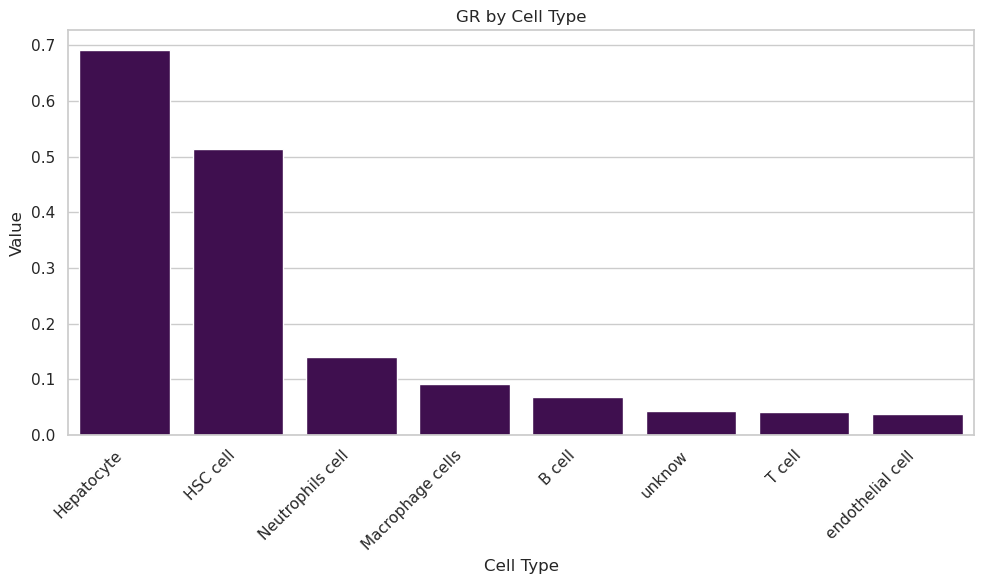

In [ ]:
melted_data = NRI_with_CCRS.melt(id_vars="Cell Type", value_vars=["STARidx"], 
                                 var_name="Metric", value_name="Value")

custom_order = [
    'Hepatocyte','HSC cell','Neutrophils cell', 'Macrophage cells', 'B cell', 
    'unknow', 'T cell', 'endothelial cell'
]

plt.figure(figsize=(10, 6))
sns.barplot(x="Cell Type", y="Value", data=melted_data, color="#44045A", order=custom_order)

plt.title("GR by Cell Type")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("figures/GR by Cell Type.pdf", format='pdf')
plt.show()

In [ ]:
ligand_ccrs = BC_results.groupby(["source", "ligand"])["CCRS_ABg1g2"].mean().reset_index()
ligand_ccrs.columns = ["Cell Type", "Gene", "CCRS_mean"]

receptor_ccrs = BC_results.groupby(["target", "receptor"])["CCRS_ABg1g2"].mean().reset_index()
receptor_ccrs.columns = ["Cell Type", "Gene", "CCRS_mean"]

ccrs_gene_df = pd.concat([ligand_ccrs, receptor_ccrs], ignore_index=True)
ccrs_gene_df = ccrs_gene_df.groupby(["Cell Type", "Gene"])["CCRS_mean"].mean().reset_index()

print(ccrs_gene_df.head())

  Cell Type   Gene  CCRS_mean
0    B cell    Adm   0.000000
1    B cell  Adrb2   0.011869
2    B cell    Agt   0.000000
3    B cell  Anxa1   0.000000
4    B cell  Apoa1   0.000000


/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


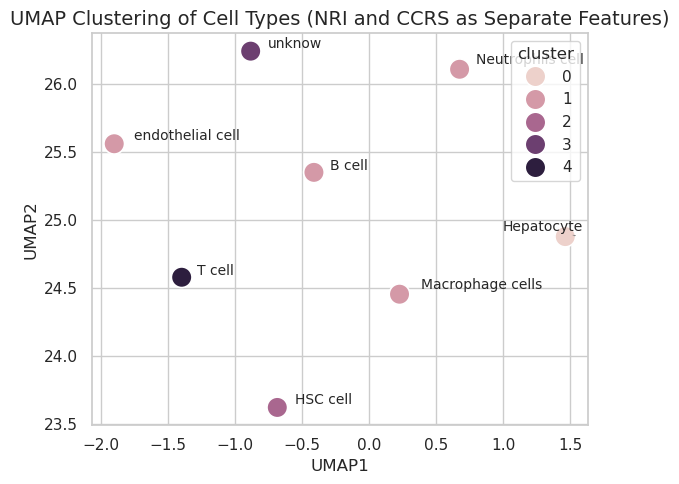

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text
import umap

RR_with_CCRS = RR_all.merge(ccrs_gene_df, on=["Cell Type", "Gene"], how="left")
RR_with_CCRS["CCRS_mean"] = RR_with_CCRS["CCRS_mean"].fillna(0)

long_nri = RR_with_CCRS.pivot_table(index="Cell Type", columns="Gene", values="RR_all", fill_value=0)
long_ccrs = RR_with_CCRS.pivot_table(index="Cell Type", columns="Gene", values="CCRS_mean", fill_value=0)

long_nri.columns = [f"{gene}_RR_all" for gene in long_nri.columns]
long_ccrs.columns = [f"{gene}_CCRS" for gene in long_ccrs.columns]

matrix = pd.concat([long_nri, long_ccrs], axis=1)

scaler = StandardScaler()
matrix_scaled = scaler.fit_transform(matrix)

kmeans = KMeans(n_clusters=5, random_state=42)
cluster_labels = kmeans.fit_predict(matrix_scaled)
matrix["cluster"] = kmeans.fit_predict(matrix_scaled)

reducer = umap.UMAP(n_neighbors=5, random_state=42, spread=1.5, min_dist=0.05)
umap_result = reducer.fit_transform(matrix_scaled)
matrix["UMAP1"] = umap_result[:, 0]
matrix["UMAP2"] = umap_result[:, 1]

plt.figure(figsize=(6, 5))
sns.set(style="whitegrid")
texts = []
sns.scatterplot(data=matrix, x="UMAP1", y="UMAP2", hue="cluster", s=220)

for i in range(matrix.shape[0]):
    texts.append(
        plt.text(matrix.iloc[i]["UMAP1"] + 0.1, 
                 matrix.iloc[i]["UMAP2"], 
                 matrix.index[i], fontsize=10)
    )
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray', lw=0.5))

plt.title("UMAP Clustering of Cell Types (NRI and CCRS as Separate Features)", fontsize=14)
plt.tight_layout()
plt.savefig("figures/UMAP_NRI_CCRS_clustering.pdf")
plt.show()

In [ ]:
ERGs_df = RR_all[RR_all["EoR_all"]>0.4][["Cell Type", "Gene", "EoR_all", "RR_all"]]
 
print(ERGs_df)

            Cell Type     Gene   EoR_all     RR_all
0          Hepatocyte     Baat  0.981002  22.563037
1          Hepatocyte      Hpd  0.824376  46.989455
2          Hepatocyte     Lrg1  0.701369  10.520531
3          Hepatocyte  Angptl3  0.916483  19.246136
4          Hepatocyte     Tdo2  0.889313  30.236658
..                ...      ...       ...        ...
485  Neutrophils cell     Lrg1  0.701369   6.312319
486  Neutrophils cell    Acaa2  0.838603   3.354412
488  Neutrophils cell   Pnpla7  0.697351   0.697351
489  Neutrophils cell     Cks2  0.572346   0.572346
490  Neutrophils cell   Atp5g1  0.807740   1.615480

[396 rows x 4 columns]


In [ ]:
cluster2_cells = matrix[matrix["cluster"] == 1].index.tolist()

subset = ERGs_df[ERGs_df["Cell Type"].isin(cluster2_cells)]

gene_counts = subset.groupby("Gene")["Cell Type"].nunique()

min_required = int(len(cluster2_cells) * 0.1)

selected_genes = gene_counts[gene_counts >= min_required].index.tolist()

In [ ]:
selected_df = ERGs_df[ERGs_df['Cell Type'] == 'HSC cell']
selected = selected_df['Gene'].tolist()

In [ ]:
# Pathway enrichment
import gseapy as gp
import pandas as pd

gene_list = selected

enr = gp.enrichr(gene_list=gene_list,
                 gene_sets=['GO_Biological_Process_2021'],
                 organism='Mouse',
                 outdir=None,
                 cutoff=0.05
                )

results = enr.results

remove_keywords = [
    "pancreatic", "glycan", "biosynthetic", "nucleotide", "telomere",
    "axon", "RNA", "DNA", "synapse", "methylation","tumor"
]

mask_remove = ~results["Term"].str.lower().str.contains('|'.join(remove_keywords))
filtered_results = results[mask_remove]

keep_keywords = [
    "immune", "inflammatory", "leukocyte", "macrophage", "cytokine",
    "chemotaxis", "T cell", "B cell", "complement", "NF-kappaB",
    "lipid", "cholesterol", "bile acid", "fatty acid", "glucose",
    "glycolysis", "oxidative", "cytochrome P450", "urea",
    "extracellular matrix", "fibroblast", "smooth muscle", "collagen",
    "TGF-beta", "wound", "remodeling", "mesenchymal",
    "endothelial", "vascular", "angiogenesis", "adhesion"
]

mask_keep = filtered_results["Term"].str.lower().str.contains('|'.join(keep_keywords))
final_results = filtered_results[mask_keep]

print(final_results[["Term", "Overlap", "Adjusted P-value", "Combined Score" ]].head(10))

                                                 Term Overlap  Adjusted P-value  Combined Score
6   positive regulation of macrophage migration (G...    2/19          0.018618      663.367179
7    regulation of macrophage chemotaxis (GO:0010758)    2/22          0.021945      542.547763
9   neutrophil activation involved in immune respo...   5/485          0.022884       58.888468
18                  fatty acid oxidation (GO:0019395)    2/59          0.058937      140.906322
24                 inflammatory response (GO:0006954)   3/230          0.058937       51.502496
25          fatty acid catabolic process (GO:0009062)    2/70          0.058937      111.056583
27  positive regulation of natural killer cell che...     1/5          0.058937      842.662296
36  negative regulation of macrophage chemotaxis (...     1/5          0.058937      842.662296
39  positive regulation of inflammatory response (...    2/89          0.058937       79.117086
44  regulation of blood vessel remodelin

In [112]:
for term in final_results["Term"].head(10):
    print(term)

positive regulation of macrophage migration (GO:1905523)
regulation of macrophage chemotaxis (GO:0010758)
neutrophil activation involved in immune response (GO:0002283)
fatty acid oxidation (GO:0019395)
inflammatory response (GO:0006954)
fatty acid catabolic process (GO:0009062)
positive regulation of natural killer cell chemotaxis (GO:2000503)
negative regulation of macrophage chemotaxis (GO:0010760)
positive regulation of inflammatory response (GO:0050729)
regulation of blood vessel remodeling (GO:0060312)


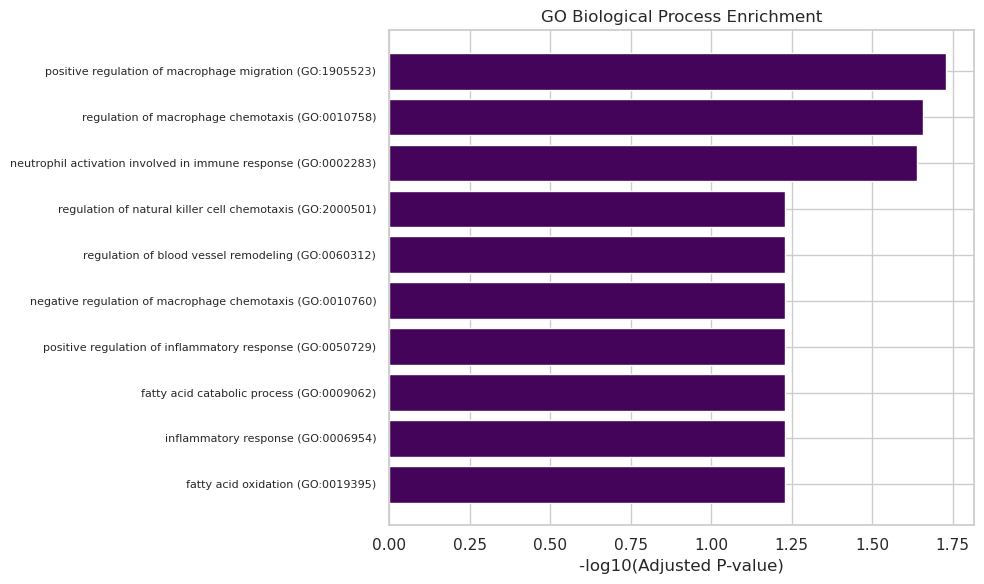

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as colors

top_terms = final_results.sort_values("Adjusted P-value").head(10)
top_terms["minus_log10_padj"] = -np.log10(top_terms["Adjusted P-value"])

max_clip = np.percentile(top_terms["minus_log10_padj"], 80)
clipped_values = np.clip(top_terms["minus_log10_padj"], None, max_clip)

gamma = 1  
normalized = (clipped_values - clipped_values.min()) / (clipped_values.max() - clipped_values.min())
adjusted = normalized ** gamma

import matplotlib.colors as mcolors

morandi_purples = [
    '#BBCFE8',
    '#92BBD7',
    '#659BCA',
    '#376EAE',
    '#234086',
]

cmap = mcolors.LinearSegmentedColormap.from_list('morandi_purples', morandi_purples, N=256)
#cmap = cm.get_cmap(cmap_name)
colors_list = cmap(adjusted)


plt.figure(figsize=(10,6))
plt.barh(top_terms["Term"], top_terms["minus_log10_padj"], color="#44045A")
plt.xlabel('-log10(Adjusted P-value)')
plt.title('GO Biological Process Enrichment')
plt.gca().invert_yaxis()
plt.yticks(fontsize=8)


plt.tight_layout()

plt.savefig('/slurm/home/yrd/fanlab/gaomeng/NRI/QFPDD/figures/enrichment_Neutrophil.pdf', format='pdf',backend="cairo")

plt.show()


In [85]:
print(BC_results.head())


   ligand receptor  lr_means_smi            source            target  \
0  S100a9     Cd68      3.733107  Neutrophils cell  Macrophage cells   
1  S100a9     Cd68      3.309133  Neutrophils cell            unknow   
2  S100a9     Cd68      3.153457  Neutrophils cell  Neutrophils cell   
3  S100a8     Cd68      3.102880  Neutrophils cell  Macrophage cells   
4  S100a8     Cd69      3.086715  Neutrophils cell            T cell   

   lr_means_model  lr_means  IAB_g1g2_smi  IAB_g1g2_model  IAB_g1g2_ctrl  \
0        3.712873  3.457438      3.733107        3.712873       3.457438   
1        3.304921  3.029716      3.309133        3.304921       3.029716   
2        3.121221  2.869539      3.153457        3.121221       2.869539   
3        3.093520  2.726697      3.102880        3.093520       2.726697   
4        3.042480  2.780743      3.086715        3.042480       2.780743   

   RLAB_g1g2  EoRCAB_g1g2  BC_AB_g1  BC_AB_g2  BC_AB_g1g2  CCRS_ABg1g2  
0  -0.079213            0  0.012661  

In [ ]:
filtered__df = BC_results[BC_results["BC_AB_g1g2"] != 0]

unique_lr_pairs = filtered__df[["ligand", "receptor",'source','target']].drop_duplicates().reset_index(drop=True)
merged_results["Ir"] = merged_results[["lr_means_smi", "lr_means_model", "lr_means"]].mean(axis=1)

lr_with_ir = merged_results[["ligand", "receptor", "source", "target", "Ir"]].drop_duplicates()

unique_lr_pairs = pd.merge(unique_lr_pairs, lr_with_ir, on=["ligand", "receptor", "source", "target"], how="left")

print(unique_lr_pairs.head())


In [ ]:

nodes_df = pd.read_csv('PPI_merged_for_Cytoscape/nodes.tsv', sep='\t')

ligands = filtered__df[['ligand', 'source']].rename(columns={'ligand': 'gene', 'source': 'cell_type'})
receptors = filtered__df[['receptor', 'target']].rename(columns={'receptor': 'gene', 'target': 'cell_type'})

ligrec = pd.concat([ligands, receptors], ignore_index=True)

gene2ct = ligrec.groupby('gene')['cell_type'].apply(lambda x: ';'.join(sorted(set(x)))).reset_index()
gene2ct = gene2ct.rename(columns={'cell_type': 'cell_types'})

existing_genes = set(nodes_df['gene'])
new_genes_df = gene2ct[~gene2ct['gene'].isin(existing_genes)].copy()

for col in nodes_df.columns:
    if col not in new_genes_df.columns:
        new_genes_df[col] = None

new_genes_df = new_genes_df[nodes_df.columns]

final_nodes = pd.concat([nodes_df, new_genes_df], ignore_index=True)
final_nodes.to_csv('PPI_merged_for_Cytoscape/nodes_with_LR.tsv', sep='\t', index=False)

/tmp/ipykernel_29036/3316232174.py:27: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


In [ ]:
import pandas as pd

edges_df = pd.read_csv("PPI_merged_for_Cytoscape/edges.tsv", sep="\t")

unique_lr_pairs["ligand_upper"] = unique_lr_pairs["ligand"].str.upper()
unique_lr_pairs["receptor_upper"] = unique_lr_pairs["receptor"].str.upper()
unique_lr_pairs["lr_pair"] = unique_lr_pairs.apply(
    lambda row: tuple(sorted([row["ligand_upper"], row["receptor_upper"]])), axis=1
)

ir_means = unique_lr_pairs.groupby("lr_pair")["Ir"].mean().reset_index()
ir_means.columns = ["lr_pair", "Ir_mean"]
lr_set = set(ir_means["lr_pair"])

edges_df["source_upper"] = edges_df["source"].str.upper()
edges_df["target_upper"] = edges_df["target"].str.upper()
edges_df["edge_pair"] = edges_df.apply(
    lambda row: tuple(sorted([row["source_upper"], row["target_upper"]])),
    axis=1
)

edges_df["is_LR"] = edges_df["edge_pair"].isin(lr_set)
edges_df["Edge_type"] = edges_df["is_LR"].map({True: "Ligand-Receptor", False: "PPI"})

existing_edges = set(edges_df["edge_pair"])
missing_pairs = lr_set - existing_edges

missing_edges = pd.DataFrame(
    list(missing_pairs), columns=["source", "target"]
)
missing_edges["is_LR"] = True
missing_edges["Edge_type"] = "Ligand-Receptor"
missing_edges["edge_pair"] = missing_edges.apply(
    lambda row: tuple(sorted([row["source"].upper(), row["target"].upper()])), axis=1
)

combined_edges = pd.concat([
    edges_df,
    missing_edges
], ignore_index=True)

final_edges = pd.merge(
    combined_edges,
    ir_means,
    how="left",
    left_on="edge_pair",
    right_on="lr_pair"
).drop(columns=["source_upper", "target_upper", "lr_pair", "edge_pair"])

final_edges.to_csv("PPI_merged_for_Cytoscape/edges_3.tsv", sep="\t", index=False)


In [ ]:
n_matched = edges_df["is_LR"].sum()
print(edges_df[edges_df["is_LR"]].head(20))

In [ ]:
BC_results.columns = BC_results.columns.str.strip()

source_genes = edges_df[edges_df["is_LR"]]["source"].unique()

matched_rows = BC_results[
    BC_results["ligand"].isin(source_genes) | BC_results["receptor"].isin(source_genes)
]

matched_df = matched_rows[["ligand", "receptor", "RLAB_g1g2"]].copy()

matched_df = matched_df.drop_duplicates().reset_index(drop=True)


lr_mean_df = (
    matched_df
    .groupby(["ligand", "receptor"], as_index=False)
    .agg({"RLAB_g1g2": "mean"})
    .sort_values("RLAB_g1g2", ascending=False)
)
print(lr_mean_df.head(20))

In [ ]:
lr_mean_df.columns = lr_mean_df.columns.str.strip()

lr_edges = edges_df[edges_df["is_LR"]].copy()

def make_key(a, b):
    return tuple(sorted([a, b]))

lr_edges["pair_key"] = lr_edges.apply(lambda row: make_key(row["source"], row["target"]), axis=1)
lr_mean_df["pair_key"] = lr_mean_df.apply(lambda row: make_key(row["ligand"], row["receptor"]), axis=1)

merged_df = pd.merge(
    lr_edges,
    lr_mean_df[["pair_key", "RLAB_g1g2"]],
    on="pair_key",
    how="left"
)

key_pairs_df = merged_df[["source", "target", "RLAB_g1g2"]].copy()
key_pairs_df.rename(columns={"RLAB_g1g2": "RLAB_g1g2"}, inplace=True)

print(key_pairs_df.head(10))

In [ ]:
ccl2_df = lr_mean_df[(lr_mean_df["ligand"] == "Ccl2") | (lr_mean_df["receptor"] == "Ccl2")].copy()
print(ccl2_df.head(10))

chord_df = pd.DataFrame({
    "source": ccl2_df["ligand"],
    "target": ccl2_df["receptor"],
    "value": ccl2_df["RLAB_g1g2"]
})

chord_df.to_csv("/slurm/home/yrd/fanlab/gaomeng/NRI/QFPDD/Ccl2_chord_data.csv", index=False)

  ligand receptor  RLAB_g1g2       pair_key
6   Ccl2    Cxcr3   1.218064  (Ccl2, Cxcr3)
1   Ccl2     Ccr1   1.165183   (Ccl2, Ccr1)
3   Ccl2     Ccr3   0.845155   (Ccl2, Ccr3)
2   Ccl2     Ccr2   0.680892   (Ccl2, Ccr2)
4   Ccl2     Ccr5   0.177082   (Ccl2, Ccr5)
5   Ccl2     Ccr9  -0.353308   (Ccl2, Ccr9)
